In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import scanpy as sc
import os, warnings 
warnings.filterwarnings('ignore') 

from glob import glob
from setup import *
import stan

dpi = 300
fontsize = 8
figsize = 2.5

# High-resolution figures for the manuscript

In [2]:
# sample_list = []
# for x in glob('data/Ravi_processed/gbm_qc/*'):
#     sample_list.append(x.split(r'/')[-1][:-5])
# sample_list.sort()
sample_list = ['SNU18Afrozen', 'SNU24A', 'SNU27B']

In [4]:
adatas = dict() # input of STAN
for sample in sample_list:
    adatas[sample] = sc.read_h5ad(f"data/Sonpatki_processed/{sample}.h5ad")
    sc.pp.normalize_total(adatas[sample])
    sc.pp.log1p(adatas[sample])
    
adatas_tfa = dict()
for sample in sample_list:
    adata = sc.read_h5ad(f"results/sonpatki_tfa/{sample}.h5ad")
    adatas_tfa[sample] = stan.get_activity(adata, key='tfa_stan')
    
adatas_pwa = dict()
for sample in sample_list:
    adata = sc.read_h5ad(f"results/sonpatki_pwa/{sample}.h5ad")
    adatas_pwa[sample] = stan.get_activity(adata, key='pwa_stan')

adatas_d2c = dict()
for sample in sample_list:
    adatas_d2c[sample] = sc.read_h5ad(f"results/sonpatki_d2c/{sample}.h5ad")

## Sample information

In [5]:
def plot_stain(adata, sample, path='plots_website/he_stain'):
    fig, ax = plt.subplots(1, 1, figsize=(figsize, figsize), dpi=dpi)
    plt.rc('font', size=fontsize) 
    sc.pl.spatial(adata, ax=ax, show=False, title=sample)

    ax.set_xlabel("")
    ax.set_ylabel("")
    plt.tight_layout(pad=1)
    plt.savefig(f'{path}/{sample}.pdf')
    # plt.close()
    return

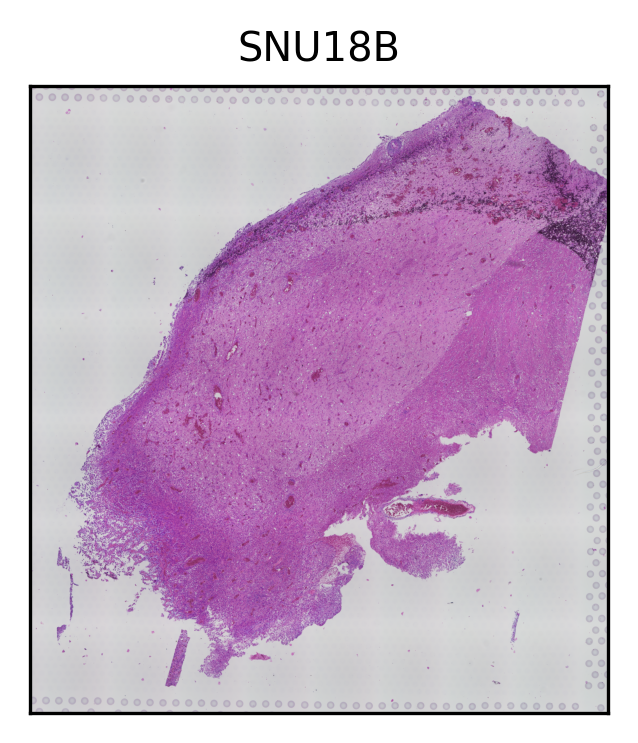

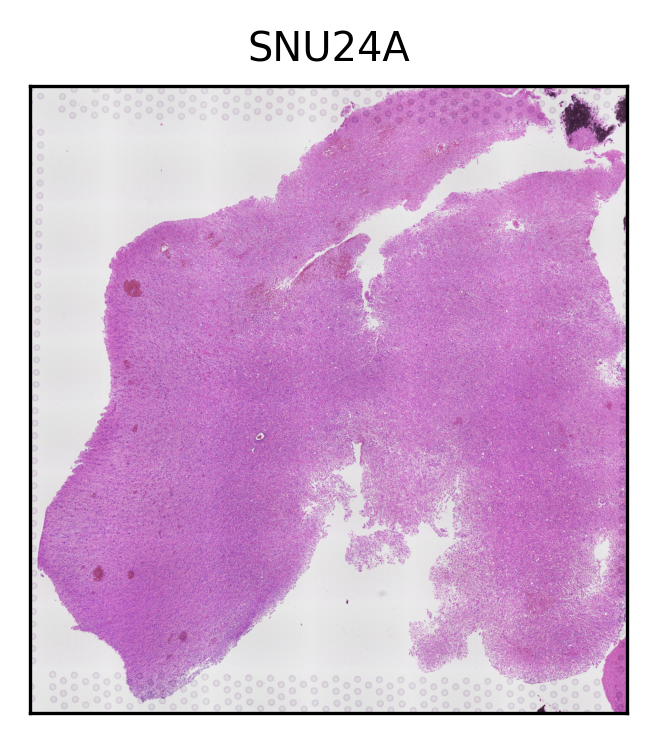

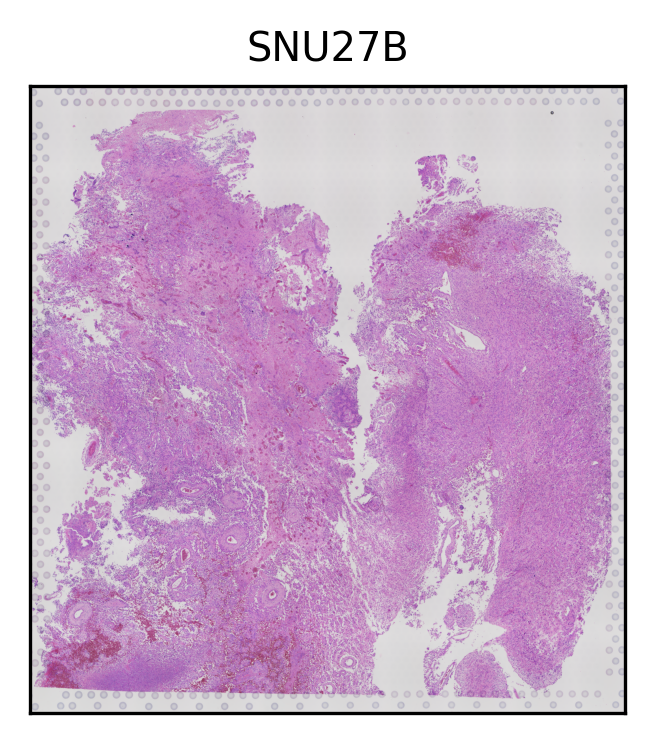

In [6]:
for sample in sample_list:
    path = f'plots_manuscript/{sample}'
    if not os.path.exists(path):
        os.mkdir(path)
    plot_stain(adatas[sample], sample, path)

## mRNA plots

In [7]:
def plot_spatial_expression(adata, sample, gene, vmax, path='plots_website/mrna'):
    title = f"{gene} expression\nMoran's I = {moran_mran_df.loc[gene, sample]:.2f}"
    fig, ax = plt.subplots(1, 1, figsize=(figsize, figsize), dpi=dpi)
    plt.rc('font', size=fontsize) 
    sc.pl.spatial(adata, color=gene, alpha_img=0, ax=ax, show=False, cmap="viridis", 
                  legend_fontsize=fontsize, size=1.8,
                  vmin=adata.X.min(), vmax=vmax
                 )
    cbar = ax.collections[0].colorbar
    cbar.ax.tick_params(labelsize=fontsize)
    ax.set_title(title, fontsize=fontsize)
    ax.set_xlabel("")
    ax.set_ylabel("")

    plt.tight_layout(pad=1)
    
    # Save the plot
    plt.savefig(f'{path}/mrna_{gene}.pdf')
    plt.close()

In [8]:
# fname = 'dataframes/morani_ravi/mrna_lr_per_sample.csv'
# moran_mran_df = pd.read_csv(fname, index_col=0)

marker_genes = ['VIM', 'CD44', 'IGFBP5', 
                'VEGFA', 'CAV1', 'LDHA', 'CD74', 'B2M',
                'SOX2', 'SOX10', 'SMAD4', 'FOS', 'JUN', 'ATF3']
adatas_markers = dict()
for sample in sample_list:
    adata = adatas[sample]
    adatas_markers[sample] = adata[:, [gene for gene in marker_genes if gene in adata.var_names]]
moran_mran_df = stan.compute_morans_i(adatas_markers)

  0%|          | 0/100 [00:00<?, ?/s]

  0%|          | 0/100 [00:00<?, ?/s]

  0%|          | 0/100 [00:00<?, ?/s]

In [12]:
sample = 'SNU27B'
adata = adatas[sample]
adata.to_df()[['VEGFA', 'CAV1', 'LDHA']].max()

KeyError: "['LDHA'] not in index"

In [35]:
for gene in ['VEGFA', 'CAV1', 'LDHA']: ## remove [:3]
    path = f'plots_manuscript/{sample}'
    if not os.path.exists(path):
        os.mkdir(path)
    plot_spatial_expression(adata, sample, gene, vmax=3.7, path=path)

In [36]:
sample = 'UKF313'
adata = adatas[sample]
adata.to_df()[['CD74', 'B2M']].max()

CD74    3.066537
B2M     3.549026
dtype: float32

In [37]:
for gene in ['CD74', 'B2M']: ## remove [:3]
    path = f'plots_manuscript/{sample}'
    if not os.path.exists(path):
        os.mkdir(path)
    plot_spatial_expression(adata, sample, gene, vmax=3.5, path=path)

## TF plots

In [38]:
def plot_spatial_activity(adata, sample, tf, path='plots_website/transcription'):
    title = f"{tf} activity\nMoran's I = {moran_tfa_df.loc[tf, sample]:.2f}"
    fig, ax = plt.subplots(1, 1, figsize=(figsize, figsize), dpi=dpi)
    plt.rc('font', size=fontsize) 
    sc.pl.spatial(adata, color=tf, alpha_img=0, ax=ax, show=False, cmap="plasma", 
                  legend_fontsize=fontsize, size=1.8,)
    cbar = ax.collections[0].colorbar
    cbar.ax.tick_params(labelsize=fontsize)
    ax.set_title(title, fontsize=fontsize)
    ax.set_xlabel("")
    ax.set_ylabel("")
    plt.tight_layout(pad=1)
    
    # Save the plot
    plt.savefig(f'{path}/tfa_{tf}.pdf')
    plt.close()

In [20]:
fname = 'dataframes/morani_ravi/tfa_per_sample.csv'
moran_tfa_df = pd.read_csv(fname, index_col=0)

In [39]:
for tf in ['SOX2', 'HIF1A']: ## remove [:3]
    for sample in ['UKF260', 'UKF275']:
        path = f'plots_manuscript/{sample}'
        if not os.path.exists(path):
            os.mkdir(path)
        plot_spatial_activity(adatas_tfa[sample], sample, tf, path=path)

In [40]:
for tf in ['STAT3']: ## remove [:3]
    for sample in ['UKF313']:
        path = f'plots_manuscript/{sample}'
        if not os.path.exists(path):
            os.mkdir(path)
        plot_spatial_activity(adatas_tfa[sample], sample, tf, path=path)

## Pathway plots

In [42]:
def plot_spatial_activity_pdf(adata, sample, pathway, path='plots_website/pathway'):
    title = f"{hallmarks[pathway]} activity\nMoran's I = {moran_pwa_df.loc[pathway, sample]:.2f}"
    fig, ax = plt.subplots(1, 1, figsize=(figsize, figsize), dpi=dpi)
    plt.rc('font', size=fontsize) 
    sc.pl.spatial(adata, color=pathway, alpha_img=0, ax=ax, show=False, cmap="rocket", 
                  legend_fontsize=fontsize, size=1.8)
    ax.set_title(title, fontsize=fontsize)
    ax.set_xlabel("")
    ax.set_ylabel("")
    plt.tight_layout(pad=1)
    plt.savefig(f'{path}/pwa_{hallmarks[pathway]}.pdf')
    plt.close()

In [25]:
fname = 'dataframes/morani_ravi/pwa_per_sample.csv'
moran_pwa_df = pd.read_csv(fname, index_col=0)

In [43]:
for sample in ['UKF260']:
    adata = adatas_pwa[sample]
    for pathway in ['HALLMARK_EPITHELIAL_MESENCHYMAL_TRANSITION']:
        path = f'plots_manuscript/{sample}'
        if not os.path.exists(path):
            os.mkdir(path)
        plot_spatial_activity_pdf(adata, sample, pathway, path)

In [44]:
for sample in ['UKF275']:
    adata = adatas_pwa[sample]
    for pathway in ['HALLMARK_HYPOXIA']:
        path = f'plots_manuscript/{sample}'
        if not os.path.exists(path):
            os.mkdir(path)
        plot_spatial_activity_pdf(adata, sample, pathway, path)

In [45]:
for sample in ['UKF313']:
    adata = adatas_pwa[sample]
    for pathway in ['HALLMARK_TNFA_SIGNALING_VIA_NFKB']:
        path = f'plots_manuscript/{sample}'
        if not os.path.exists(path):
            os.mkdir(path)
        plot_spatial_activity_pdf(adata, sample, pathway, path)

## Drug plots

In [48]:
def plot_spatial_score_pdf(adata, sample, drug, path='plots_website/drug'):
    d1, d2 = drug.split('|')
    d3 = split_at_natural_break(d2)
    title = f"{d1} {d3}\nMoran's I = {moran_d2c_df.loc[drug, sample]:.2f}"
    
    fig, ax = plt.subplots(1, 1, figsize=(figsize, figsize), dpi=dpi)
    plt.rc('font', size=fontsize) 
    sc.pl.spatial(adata, color=drug, alpha_img=0, ax=ax, show=False, cmap="inferno", 
                  legend_fontsize=fontsize, size=1.8)
    ax.set_title(title, fontsize=fontsize)
    ax.set_xlabel("")
    ax.set_ylabel("")
    plt.tight_layout(pad=1)
    plt.savefig(f'{path}/d2c_{d1}.pdf')
    plt.close()

In [30]:
marker_genes = ['CHEMBL1201825|RANIBIZUMAB', 'CHEMBL1201421|PEGAPTANIB SODIUM',
               'CHEMBL1201583|BEVACIZUMAB', 'CHEMBL3707357|BROLUCIZUMAB']
adatas_markers = dict()
for sample in sample_list:
    adata = adatas_d2c[sample]
    adatas_markers[sample] = adata[:, [gene for gene in marker_genes if gene in adata.var_names]]
moran_d2c_df = stan.compute_morans_i(adatas_markers)

  0%|          | 0/100 [00:00<?, ?/s]

  0%|          | 0/100 [00:00<?, ?/s]

  0%|          | 0/100 [00:00<?, ?/s]

  0%|          | 0/100 [00:00<?, ?/s]

In [49]:
# fontsize = 7.5
for sample in ['UKF260']: ## remove [:3]
    adata = adatas_d2c[sample]
    for drug in ['CHEMBL1201825|RANIBIZUMAB', 'CHEMBL1201421|PEGAPTANIB SODIUM']: ## remove [:3]
        path = f'plots_manuscript/{sample}'
        if not os.path.exists(path):
            os.mkdir(path)
        plot_spatial_score_pdf(adata, sample, drug, path)

In [50]:
for sample in ['UKF275']: ## remove [:3]
    adata = adatas_d2c[sample]
    for drug in ['CHEMBL1201583|BEVACIZUMAB', 'CHEMBL3707357|BROLUCIZUMAB']: ## remove [:3]
        path = f'plots_manuscript/{sample}'
        if not os.path.exists(path):
            os.mkdir(path)
        plot_spatial_score_pdf(adata, sample, drug, path)

## Additional Samples

In [16]:
fontsize = 10
sample = 'UKF269'
adata = adatas[sample]
adata.to_df()[['SOX2', 'SOX10', 'SMAD4', 'FOS', 'JUN', 'ATF3']].max()

SOX2     2.533823
SOX10    2.752727
SMAD4    2.374739
FOS      3.388171
JUN      2.796682
ATF3     2.129487
dtype: float32

In [17]:
for gene in ['SOX2', 'SOX10', 'SMAD4', 'FOS', 'JUN', 'ATF3']: 
    path = f'plots_manuscript/{sample}'
    if not os.path.exists(path):
        os.mkdir(path)
    plot_spatial_expression(adata, sample, gene, vmax=2.5, path=path)

In [ ]:
for tf in ['SOX2', 'SOX10', 'SMAD4', 'FOS', 'JUN', 'ATF3']: 
    for sample in ['UKF269']:
        path = f'plots_manuscript/{sample}'
        if not os.path.exists(path):
            os.mkdir(path)
        plot_spatial_activity(adatas_tfa[sample], sample, tf, path=path)